# Phần 3 (Giai đoạn 2). Thu thập Điểm chuẩn, Chỉ tiêu và Kiểm toán Chất lượng Dữ liệu (`2_scrape_diemchuan.py`, `3_scrape_chitieu.py`)

Notebook này trình bày trọn vẹn **Giai đoạn 2** của dự án: thu thập tự động lịch sử Điểm chuẩn của 34 trường đại học tại Hà Nội (`2_scrape_diemchuan.py`), chuẩn hóa và nạp Chỉ tiêu tuyển sinh (`3_scrape_chitieu.py`), đồng thời thực hiện **kiểm toán chất lượng dữ liệu gốc theo 6 chiều DAMA UK** (cùng hai tệp tham chiếu `Tier list.xlsx` và `trend_nganh_google.csv`).

Toàn bộ mã nguồn được chia thành **từng đoạn code nhỏ (4–12 dòng)** để làm rõ tác dụng kỹ thuật của mỗi thao tác trước khi bước sang giai đoạn làm sạch sâu trên SQL ở File 4 (`4_data_cleaning.py`).

**Trình tự thực hiện:**

    Giai đoạn 2. Thu thập Dữ liệu Tuyển sinh & Kiểm toán Chất lượng Gốc
    ├── 3.1 Nguồn dữ liệu Giai đoạn 2 & Khung đánh giá 6 chiều DAMA UK
    ├── 3.2 Bóc tách từng bước thu thập Điểm chuẩn (2_scrape_diemchuan.py)
    ├── 3.3 Bóc tách từng bước nạp Chỉ tiêu tuyển sinh (3_scrape_chitieu.py)
    ├── 3.4 Kiểm toán dữ liệu thiếu (Completeness) & Trùng lặp (Uniqueness)
    ├── 3.5 Kiểm toán miền giá trị (Validity) & Nhất quán liên kết bảng (Consistency)
    ├── 3.6 Thống kê mô tả cơ bản, Rào ngoại lai IQR & Trực quan hóa dữ liệu
    └── 3.7 Bảng tổng hợp rủi ro dữ liệu bàn giao sang Giai đoạn 3 (File 4)

---
### 3.1. Nguồn dữ liệu Giai đoạn 2 và Khung kiểm toán DAMA UK

Nếu phổ điểm thi THPT ở Giai đoạn 1 phản ánh *nguồn cung điểm số của thí sinh*, thì Giai đoạn 2 thu thập dữ liệu phản ánh *nguồn cầu và ngưỡng tuyển sinh của các trường đại học*:

- **Lịch sử Điểm chuẩn (`2_scrape_diemchuan.py` $\rightarrow$ `Staging_DiemChuan` / `DiemChuanTruong`):** Điểm trúng tuyển xét điểm thi THPT giai đoạn 2022–2025 của 34 trường đại học tại Hà Nội.
- **Chỉ tiêu tuyển sinh (`3_scrape_chitieu.py` $\rightarrow$ `ChiTieuTruong`):** Đọc từ `data_raw/Chỉ tiêu.xlsx` (3.360 dòng, giai đoạn 2023–2026) gồm tổng chỉ tiêu ngành và tỷ lệ phần trăm dành riêng cho xét điểm thi THPT.
- **Hai tệp tham chiếu bổ trợ:** `data_raw/Tier list.xlsx` (phân hạng Tier 1, Tier 2, Tier 3) và `data_raw/trend_nganh_google.csv` (xu hướng tìm kiếm Google Trends 2021–2026).

| Chiều chất lượng (DAMA UK) | Câu hỏi kiểm toán trên dữ liệu vừa thu thập | Mục thực hiện |
|---|---|---|
| **Completeness** (Đầy đủ) | Các bảng Điểm chuẩn, Chỉ tiêu, Tier list, Google Trends có ô trống (`NULL`/`NaN`) không? | Mục 3.4 |
| **Uniqueness** (Duy nhất) | Có hiện tượng trùng khóa tổ hợp (cơ sở Bắc/Nam) hoặc lặp mã trường trong `Tier list.xlsx` không? | Mục 3.4 |
| **Validity** (Hợp lệ) | Điểm chuẩn có nằm trong thang 30 không? Cột chỉ tiêu và tỷ lệ THPT có dính chuỗi chữ hay bằng `0` không? | Mục 3.3, 3.5 |
| **Consistency** (Nhất quán) | Mã tổ hợp Tin học (`A0T`/`D0T` vs `X06`/`X26`) và tên ngành giữa Chỉ tiêu – Điểm chuẩn khớp bao nhiêu %? | Mục 3.5 |
| **Timeliness** (Kịp thời) | Độ phủ các năm (2022–2026) có đảm bảo nguyên tắc chống rò rỉ dữ liệu (Data Leakage) khi dự báo 2026? | Mục 3.6, 3.7 |
| **Accuracy** (Chính xác) | Các điểm vượt rào ngoại lai `1.5 * IQR` ở cột chỉ tiêu là lỗi nhập liệu hay quy mô tuyển sinh thật? | Mục 3.6 |

---
### 3.2. Bóc tách quy trình Thu thập Lịch sử Điểm chuẩn (`2_scrape_diemchuan.py`)

**Đoạn code nhỏ 1 (Phần 1 & Phần 2 trong `2_scrape_diemchuan.py`) — Khai báo thư viện, danh sách 34 trường (`truong_dict`), 4 năm lịch sử (`years`) và `headers`:** Mỗi mã trường chuẩn được gắn với `school_id` tương ứng trên hệ thống API của Tuyensinh247.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'báo cáo dự án':
    os.chdir('..')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import os
import time
import requests
import pandas as pd
import numpy as np
from sqlalchemy import create_engine, text
from sqlalchemy.types import NVARCHAR, INTEGER, VARCHAR, FLOAT
from config import DB_CONNECTION_STRING

engine = create_engine(DB_CONNECTION_STRING)

In [2]:
truong_dict = {
    'BKA': 302, 'BVH': 227, 'DCN': 308, 'DKH': 328, 'DKK': 356, 'FBU': 474,
    'GHA': 330, 'HBT': 224, 'HNM': 126, 'HPN': 556, 'HQT': 246, 'HTC': 258,
    'HVN': 562, 'KHA': 357, 'KMA': 245, 'LPH': 368, 'NHF': 336, 'NHH': 247,
    'NTH': 382, 'PKA': 423, 'QHE': 352, 'QHF': 380, 'QHI': 311, 'QHL': 266,
    'QHS': 533, 'QHT': 346, 'QHX': 348, 'QHY': 471, 'SPH': 411, 'TLA': 421,
    'TMU': 426, 'XDA': 443, 'YHB': 448, 'YTC': 452
}
years = [2025, 2024, 2023, 2022]
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) Chrome/120.0.0.0'}
print(f"Tổng số trường đại học Hà Nội khai báo: {len(truong_dict)} trường | Các năm: {years}")

Tổng số trường đại học Hà Nội khai báo: 34 trường | Các năm: [2025, 2024, 2023, 2022]

**Đoạn code nhỏ 2 (Phần 3 trong `2_scrape_diemchuan.py`) — Cấu trúc đường dẫn API JSON:** Thay vì bóc tách thẻ HTML dễ hỏng khi trang web đổi giao diện, kịch bản gọi thẳng API JSON với tham số `method_id=1` (lọc riêng phương thức Xét điểm thi tốt nghiệp THPT).

In [3]:
ma_truong_mau, school_id_mau, year_mau = 'BKA', truong_dict['BKA'], 2025
url_mau = f"https://diemthi.tuyensinh247.com/api/common/cutoff-score?school_id={school_id_mau}&method_id=1&year={year_mau}"
print("URL API mẫu:", url_mau)

URL API mẫu: https://diemthi.tuyensinh247.com/api/common/cutoff-score?school_id=302&method_id=1&year=2025

**Đoạn code nhỏ 3 (Phần 4 trong `2_scrape_diemchuan.py`) — Minh họa kỹ thuật tách khối gộp bằng `.str.split(';')` và `.explode('ma_xet_tuyen')`:** Trên cổng dữ liệu gốc, một ngành xét nhiều tổ hợp được ghi gộp thành chuỗi `"A00; A01; D01"`. Đoạn lệnh dưới đây tách chuỗi và nhân bản thành từng dòng tổ hợp độc lập để nối khớp được với bảng phổ điểm.

In [4]:
df_mau_tach = pd.DataFrame([
    {'nam_hoc': 2025, 'ma_truong': 'QHI', 'chuong_trinh_dao_tao': 'Công nghệ thông tin', 'ma_xet_tuyen': 'A00; A01; X06', 'diem_chuan': '27.80'}
])
df_mau_tach['diem_chuan'] = pd.to_numeric(df_mau_tach['diem_chuan'], errors='coerce')
df_mau_tach = df_mau_tach.dropna(subset=['diem_chuan'])
df_mau_tach = df_mau_tach[df_mau_tach['diem_chuan'] <= 30]
df_mau_tach['ma_xet_tuyen'] = df_mau_tach['ma_xet_tuyen'].str.split(';')
df_mau_tach = df_mau_tach.explode('ma_xet_tuyen')
df_mau_tach['ma_xet_tuyen'] = df_mau_tach['ma_xet_tuyen'].str.strip()
df_mau_tach = df_mau_tach[(df_mau_tach['ma_xet_tuyen'] != '') & (df_mau_tach['ma_xet_tuyen'].str.len() <= 5)]
print(df_mau_tach.to_string(index=False))

 nam_hoc ma_truong chuong_trinh_dao_tao ma_xet_tuyen  diem_chuan
    2025       QHI  Công nghệ thông tin          A00        27.8
    2025       QHI  Công nghệ thông tin          A01        27.8
    2025       QHI  Công nghệ thông tin          X06        27.8

**Đoạn code nhỏ 4 (Phần 5 trong `2_scrape_diemchuan.py`) — Kiểm tra dữ liệu thực tế trong `Staging_DiemChuan`:** Sau khi cào xong, Python đẩy toàn bộ dữ liệu vào bảng nháp `Staging_DiemChuan` (dùng kiểu `NVARCHAR` để giữ nguyên dấu tiếng Việt) và gọi `EXEC sp_DongBo_DiemChuanTruong`. Ta đọc trực tiếp bảng `Staging_DiemChuan` trong SQL Server để kiểm tra quy mô thu thập ban đầu.

In [5]:
df_dc_staging = pd.read_sql("SELECT * FROM Staging_DiemChuan", engine)
print(f"Quy mô bảng Staging_DiemChuan: {df_dc_staging.shape[0]:,d} dòng x {df_dc_staging.shape[1]} cột")
print("Số trường đại học thu thập được:", df_dc_staging['ma_truong'].nunique())
print("Phân bổ số dòng theo năm học  :", df_dc_staging['nam_hoc'].value_counts().sort_index().to_dict())
print("\n5 dòng mẫu đầu tiên:")
print(df_dc_staging.head(5).to_string(index=False))

Quy mô bảng Staging_DiemChuan: 13,368 dòng x 5 cột
Số trường đại học thu thập được: 34
Phân bổ số dòng theo năm học  : {2022: 2294, 2023: 2410, 2024: 2856, 2025: 5808}

5 dòng mẫu đầu tiên:
 nam_hoc ma_truong              chuong_trinh_dao_tao ma_xet_tuyen  diem_chuan
    2025       BKA Kỹ thuật Thực phẩm (CT tiên tiến)          A00        21.0
    2025       BKA Kỹ thuật Thực phẩm (CT tiên tiến)          B00        21.0
    2025       BKA Kỹ thuật Thực phẩm (CT tiên tiến)          D07        21.0
    2025       BKA Kỹ thuật Thực phẩm (CT tiên tiến)          B03        21.0
    2025       BKA Kỹ thuật Thực phẩm (CT tiên tiến)          C01        21.0

---
### 3.3. Bóc tách quy trình Chuẩn hóa và Nạp Chỉ tiêu Tuyển sinh (`3_scrape_chitieu.py`)

**Đoạn code nhỏ 1 (Bước 1 trong `3_scrape_chitieu.py`) — Đọc tệp `data_raw/Chỉ tiêu.xlsx` và kiểm tra kiểu dữ liệu gốc:**

In [6]:
excel_path = 'data_raw/Chỉ tiêu.xlsx'
df_excel_raw = pd.read_excel(excel_path)
print(f"Kích thước tệp Chỉ tiêu.xlsx: {df_excel_raw.shape}")
print("Kiểu dữ liệu các cột gốc:")
print(df_excel_raw.dtypes)

Kích thước tệp Chỉ tiêu.xlsx: (3360, 6)
Kiểu dữ liệu các cột gốc:
nam_hoc                  int64
ma_truong                  str
chuong_trinh_dao_tao       str
ma_to_hop                  str
tong_chi_tieu           object
ty_le_chi_tieu_thpt     object
dtype: object

**Nhận xét phát hiện quan trọng:** Cả hai cột số là `tong_chi_tieu` và `ty_le_chi_tieu_thpt` đều bị đọc thành kiểu chuỗi văn bản (`object` / `str`) do trong Excel có dòng gõ dấu phẩy thập phân kiểu Việt Nam (`'0,4'`) và khoảng ước lượng (`'~100-240'`).

**Đoạn code nhỏ 2 (Bước 1 & Bước 2 trong `3_scrape_chitieu.py`) — Làm sạch cột `nam_hoc` và đổi dấu `','` thành `'.'` ở cột `ty_le_chi_tieu_thpt`:**

In [7]:
df_excel = df_excel_raw.copy()
df_excel['nam_hoc'] = pd.to_numeric(df_excel['nam_hoc'], errors='coerce')
df_excel = df_excel.dropna(subset=['nam_hoc'])
df_excel['nam_hoc'] = df_excel['nam_hoc'].astype(int)

df_excel['ty_le_chi_tieu_thpt'] = df_excel['ty_le_chi_tieu_thpt'].astype(str).str.replace(',', '.', regex=False)
df_excel['ty_le_chi_tieu_thpt'] = pd.to_numeric(df_excel['ty_le_chi_tieu_thpt'], errors='coerce').round(2)
print("Mẫu cột ty_le_chi_tieu_thpt sau chuẩn hóa:", df_excel['ty_le_chi_tieu_thpt'].head(5).tolist())

Mẫu cột ty_le_chi_tieu_thpt sau chuẩn hóa: [0.4, 0.4, 0.4, 0.4, 0.4]

**Đoạn code nhỏ 3 (Bước 3 & Bước 4 trong `3_scrape_chitieu.py`) — Đồng bộ tên cột khớp 100% với bảng `ChiTieuTruong` trong `schema.sql`:** Chép `ma_to_hop` sang `ma_xet_tuyen`, ép kiểu số nguyên cho `tong_chi_tieu` sang cột `chi_tieu` (các chuỗi khoảng ước lượng không phải số sẽ tạm về `0` nhờ `.fillna(0)`) và lọc đúng 6 cột chuẩn.

In [8]:
df_sql_preview = df_excel.copy()
if 'ma_to_hop' in df_sql_preview.columns:
    df_sql_preview['ma_xet_tuyen'] = df_sql_preview['ma_to_hop']

df_sql_preview['tong_chi_tieu'] = pd.to_numeric(df_sql_preview['tong_chi_tieu'], errors='coerce').fillna(0)
df_sql_preview['chi_tieu'] = df_sql_preview['tong_chi_tieu'].astype(int)

cols_to_keep = ['nam_hoc', 'ma_truong', 'chuong_trinh_dao_tao', 'ma_xet_tuyen', 'chi_tieu', 'ty_le_chi_tieu_thpt']
df_sql_preview = df_sql_preview[cols_to_keep]
print(df_sql_preview.head(4).to_string(index=False))

 nam_hoc ma_truong chuong_trinh_dao_tao       ma_xet_tuyen  chi_tieu  ty_le_chi_tieu_thpt
    2025       KHA          Kinh tế học A00, A01, D01, D07       100                  0.4
    2025       KHA    Kinh tế chính trị A00, A01, D01, D07        60                  0.4
    2025       KHA   Kinh tế phát triển A00, A01, D01, D07       120                  0.4
    2025       KHA       Kinh tế đầu tư A00, A01, D01, D07       200                  0.4

**Cơ chế Bước 5 trong `3_scrape_chitieu.py` (Bảo toàn Khóa ngoại & Cấu trúc bảng):**
1. Duyệt qua `unique_schools = df_sql['ma_truong'].dropna().unique()` và chạy `IF NOT EXISTS ... INSERT INTO DanhMucTruong` để không bao giờ vi phạm ràng buộc `FOREIGN KEY`.
2. Dùng `DELETE FROM ChiTieuTruong` kết hợp `df_sql.to_sql(..., if_exists='append')` thay vì `'replace'` để giữ nguyên cột `id IDENTITY(1,1)` và khóa ngoại đã thiết kế trong `schema.sql`.

Kiểm chứng bảng `ChiTieuTruong` đang lưu trong SQL Server cùng hai tệp tham chiếu `Tier list.xlsx` và `trend_nganh_google.csv`:

In [9]:
df_ct_db = pd.read_sql("SELECT * FROM ChiTieuTruong", engine)
df_tier_raw = pd.read_excel("data_raw/Tier list.xlsx")
df_trend_raw = pd.read_csv("data_raw/trend_nganh_google.csv")
print(f"ChiTieuTruong (SQL)     : {df_ct_db.shape}")
print(f"Tier list.xlsx          : {df_tier_raw.shape}")
print(f"trend_nganh_google.csv  : {df_trend_raw.shape}")

ChiTieuTruong (SQL)     : (3360, 7)
Tier list.xlsx          : (35, 4)
trend_nganh_google.csv  : (60, 4)

---
### 3.4. Kiểm toán Dữ liệu thiếu (Completeness) và Tính duy nhất (Uniqueness)

**Đoạn code nhỏ 1 — Đếm số ô khuyết (`NULL`/`NaN`) trên cả 4 nguồn dữ liệu của Giai đoạn 2:**

In [10]:
nguon_kiem_tra = {
    'Staging_DiemChuan': df_dc_staging,
    'Chỉ tiêu.xlsx (Gốc)': df_excel_raw,
    'Tier list.xlsx': df_tier_raw,
    'trend_nganh_google.csv': df_trend_raw
}
for ten, bang in nguon_kiem_tra.items():
    so_null = bang.isnull().sum().sum()
    chi_tiet = bang.isnull().sum()[bang.isnull().sum() > 0].to_dict()
    print(f"- {ten:<24}: Tổng ô trống = {so_null} {chi_tiet if so_null > 0 else ''}")

- Staging_DiemChuan       : Tổng ô trống = 0 
- Chỉ tiêu.xlsx (Gốc)     : Tổng ô trống = 0 
- Tier list.xlsx          : Tổng ô trống = 0 
- trend_nganh_google.csv  : Tổng ô trống = 0 

**Đoạn code nhỏ 2 — Kiểm tra trùng khóa Bắc/Nam trong `Staging_DiemChuan` (Rủi ro M3) và lặp mã trường trong `Tier list.xlsx`:**

In [11]:
trung_khoa_dc = df_dc_staging.duplicated(
    subset=['nam_hoc', 'ma_truong', 'chuong_trinh_dao_tao', 'ma_xet_tuyen'], keep=False
).sum()
lap_tier = df_tier_raw[df_tier_raw.duplicated(subset=['ma_truong'], keep=False)]

print(f"Số dòng trùng khóa (Năm, Trường, Ngành, Khối) trong Staging_DiemChuan: {trung_khoa_dc} dòng")
print(f"Số mã trường duy nhất trong Tier list.xlsx: {df_tier_raw['ma_truong'].nunique()} / {len(df_tier_raw)} dòng")
print("\nCác dòng bị lặp mã trường trong Tier list.xlsx:")
print(lap_tier[['ma_truong', 'ten_truong_viet_tat', 'tier_ranking']].to_string(index=False))

Số dòng trùng khóa (Năm, Trường, Ngành, Khối) trong Staging_DiemChuan: 479 dòng
Số mã trường duy nhất trong Tier list.xlsx: 33 / 35 dòng

Các dòng bị lặp mã trường trong Tier list.xlsx:
ma_truong       ten_truong_viet_tat tier_ranking
      ANS Học viện An ninh nhân dân       Tier 1
      HTC        Học viện Tài chính       Tier 2
      HTC  Học viện Tài chính (CLC)       Tier 3
      ANS Học viện An ninh nhân dân       Tier 1

**Kết luận mục 3.4:**
- Bốn nguồn dữ liệu đạt độ đầy đủ rất cao; riêng trong `Staging_DiemChuan` phát hiện các dòng trùng khóa `(nam_hoc, ma_truong, chuong_trinh_dao_tao, ma_xet_tuyen)` do một số trường (như `KMA`, `GHA`, `BVH`) công bố chung điểm chuẩn cơ sở Hà Nội và phân hiệu phía Nam dưới cùng một mã trường (sau khi khử trùng ở File 4 sẽ giảm từ **13.368** về đúng **13.120** dòng sạch).
- Trong `Tier list.xlsx` (35 dòng cho 33 trường), có 2 mã trường lặp là `ANS` và `HTC`, đồng thời thiếu 3 trường (`BVH`, `NHF`, `YHB`) — cần dùng `.drop_duplicates(subset=['ma_truong'])` và bổ sung ở Giai đoạn 3 (`4_data_cleaning.py`).

---
### 3.5. Kiểm toán Miền giá trị (Validity) và Nhất quán Liên kết bảng (Consistency)

**Đoạn code nhỏ 1 — Tìm các dòng chỉ tiêu ghi dạng khoảng ước lượng chữ trong `Chỉ tiêu.xlsx` (Rủi ro M4):**

In [12]:
ct_so = pd.to_numeric(df_excel_raw['tong_chi_tieu'], errors='coerce')
dong_khoang_chu = df_excel_raw[ct_so.isna()][['nam_hoc', 'ma_truong', 'chuong_trinh_dao_tao', 'tong_chi_tieu']]
print(f"Số dòng tong_chi_tieu chứa ký tự khoảng ước lượng: {len(dong_khoang_chu)} dòng")
print(dong_khoang_chu.to_string(index=False))

Số dòng tong_chi_tieu chứa ký tự khoảng ước lượng: 2 dòng
 nam_hoc ma_truong                                       chuong_trinh_dao_tao tong_chi_tieu
    2025       NTH Các ngành KTQT, QTĐD, KDQT, TCQT, Ngân hàng, Kế-Kiểm, Luật      ~100-240
    2025       NTH                Các ngành Ngôn ngữ (Anh, Pháp, Trung, Nhật)       ~60-160

**Đoạn code nhỏ 2 — Kiểm tra độ lệch mã tổ hợp Tin học (`X06`, `X26` vs `A0T`, `D0T` — Rủi ro M1) và tỷ lệ khớp tên ngành giữa Chỉ tiêu – Điểm chuẩn:**

In [13]:
khoi_dc_2025 = set(df_dc_staging[df_dc_staging['nam_hoc'] == 2025]['ma_xet_tuyen'].dropna().unique())
khoi_tin_dc = sorted([k for k in khoi_dc_2025 if k in ('A0T', 'D0T', 'X06', 'X26')])

ten_dc = set(zip(df_dc_staging['ma_truong'], df_dc_staging['chuong_trinh_dao_tao'].str.strip().str.lower()))
ten_ct = set(zip(df_excel_raw['ma_truong'], df_excel_raw['chuong_trinh_dao_tao'].str.strip().str.lower()))
ty_le_khop_tho = len(ten_dc & ten_ct) / len(ten_ct) * 100

print("Các mã khối Tin học xuất hiện trong Điểm chuẩn 2025:", khoi_tin_dc)
print(f"Tỷ lệ khớp nguyên văn 100% tên ngành giữa Chỉ tiêu gốc & Điểm chuẩn gốc: {ty_le_khop_tho:.2f}%")

Các mã khối Tin học xuất hiện trong Điểm chuẩn 2025: ['X06', 'X26']
Tỷ lệ khớp nguyên văn 100% tên ngành giữa Chỉ tiêu gốc & Điểm chuẩn gốc: 30.63%

**Kết luận mục 3.5:**
1. Phát hiện đúng **2 dòng chỉ tiêu khoảng ước lượng** (`~100-240` và `~60-160` của trường `NTH` năm 2025) bị ép về `0` khi nạp thô — đây là căn cứ trực tiếp của bước Vá rủi ro M4 (thay bằng trung điểm `170` và `110`) trong `4_data_cleaning.py`.
2. Tỷ lệ khớp nguyên văn tên ngành giữa hai bảng gốc chỉ đạt mức thấp (do khác cách viết hoa/thường, dấu gạch ngang, ghi chú hệ đào tạo), chứng minh sự cần thiết bắt buộc của thuật toán so khớp chuỗi gần đúng `difflib` (`cutoff = 0.90`) ở Giai đoạn 3.

---
### 3.6. Thống kê Mô tả Cơ bản, Khảo sát Ngoại lai IQR và Trực quan hóa

**Đoạn code nhỏ 1 — Lập bảng thống kê mô tả (`count, mean, std, min, 25%, 50%, 75%, max`) và kiểm tra rào ngoại lai `1.5 * IQR`:**

In [14]:
bang_thong_ke = pd.DataFrame({
    'diem_chuan_goc': df_dc_staging['diem_chuan'].describe(),
    'tong_chi_tieu': ct_so.dropna().describe(),
    'ty_le_thpt': df_excel['ty_le_chi_tieu_thpt'].describe(),
    'trend_score': df_trend_raw['trend_score'].describe()
}).round(2)
print(bang_thong_ke.to_string())

       diem_chuan_goc  tong_chi_tieu  ty_le_thpt  trend_score
count        13368.00        3358.00     3360.00        60.00
mean            23.58         138.61        0.46        59.09
std              3.01         139.77        0.13        14.46
min             15.00          10.00        0.05        22.00
25%             21.65          60.00        0.40        51.35
50%             24.10         100.00        0.50        60.29
75%             25.80         154.50        0.50        69.12
max             30.00        2089.00        0.80        84.08

In [15]:
for ten_cot, s in [('diem_chuan_goc', df_dc_staging['diem_chuan']), ('tong_chi_tieu', ct_so.dropna())]:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    ngoai_rao = ((s < lo) | (s > hi)).sum()
    print(f"- {ten_cot:<16}: Rào IQR [{lo:>6.2f}, {hi:>6.2f}] | Vượt rào: {ngoai_rao:>4d} dòng ({ngoai_rao/len(s)*100:.2f}%)")

- diem_chuan_goc  : Rào IQR [ 15.42,  32.03] | Vượt rào:   70 dòng (0.52%)
- tong_chi_tieu   : Rào IQR [-81.75, 296.25] | Vượt rào:  343 dòng (10.21%)

**Đoạn code nhỏ 2 — Trực quan hóa quy mô Chỉ tiêu THPT và Xu hướng Google Trends (2021–2026):**

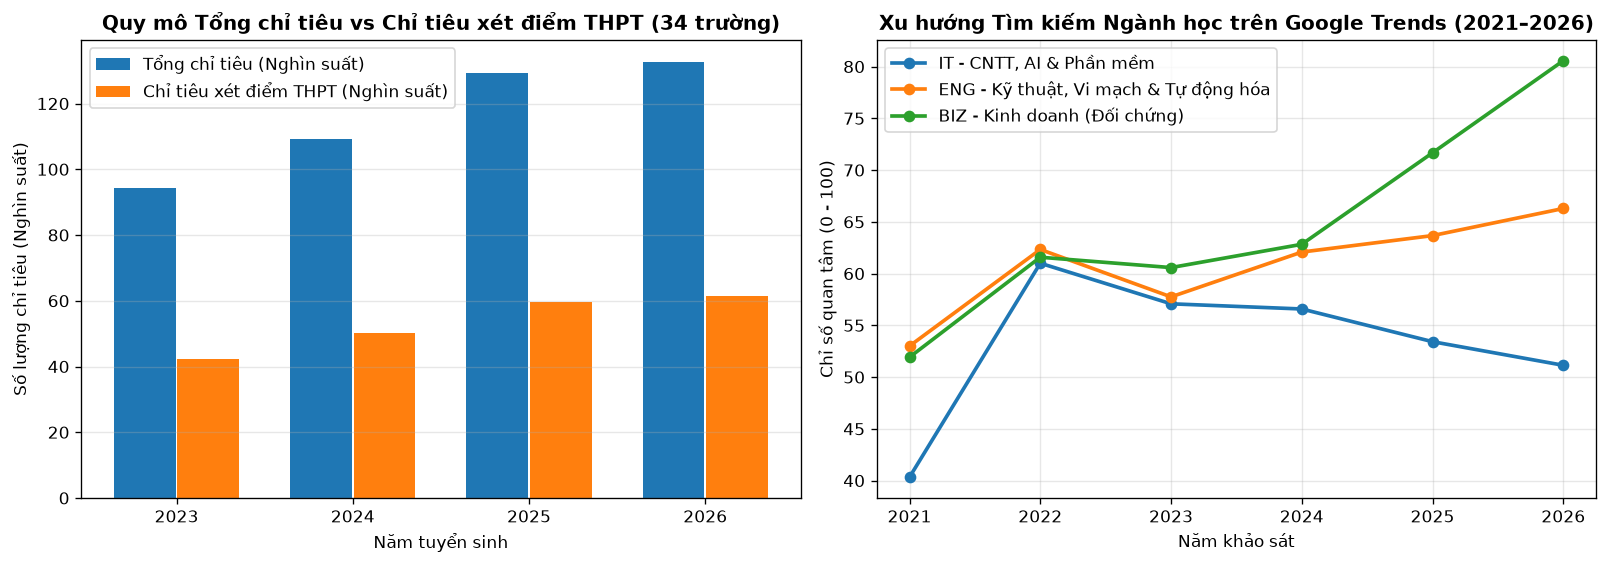

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=120)

df_ct_nam = df_sql_preview.copy()
df_ct_nam['ct_thpt'] = df_ct_nam['chi_tieu'] * df_ct_nam['ty_le_chi_tieu_thpt'].fillna(0.5)
tk_nam = df_ct_nam.groupby('nam_hoc').agg(tong=('chi_tieu', 'sum'), thpt=('ct_thpt', 'sum')).reset_index()

x = np.arange(len(tk_nam))
axes[0].bar(x - 0.18, tk_nam['tong'] / 1000, width=0.35, label='Tổng chỉ tiêu (Nghìn suất)')
axes[0].bar(x + 0.18, tk_nam['thpt'] / 1000, width=0.35, label='Chỉ tiêu xét điểm THPT (Nghìn suất)')
axes[0].set_xticks(x); axes[0].set_xticklabels(tk_nam['nam_hoc'].astype(str))
axes[0].set_title('Quy mô Tổng chỉ tiêu vs Chỉ tiêu xét điểm THPT (34 trường)', fontweight='bold')
axes[0].set_xlabel('Năm tuyển sinh'); axes[0].set_ylabel('Số lượng chỉ tiêu (Nghìn suất)')
axes[0].grid(axis='y', alpha=0.3); axes[0].legend()

for ma, nhan in [('IT', 'IT - CNTT, AI & Phần mềm'), ('ENG', 'ENG - Kỹ thuật, Vi mạch & Tự động hóa'), ('BIZ', 'BIZ - Kinh doanh (Đối chứng)')]:
    sub = df_trend_raw[df_trend_raw['ma_nganh_chuan'] == ma].sort_values('nam_hoc')
    axes[1].plot(sub['nam_hoc'].astype(str), sub['trend_score'], marker='o', linewidth=2.2, label=nhan)
axes[1].set_title('Xu hướng Tìm kiếm Ngành học trên Google Trends (2021–2026)', fontweight='bold')
axes[1].set_xlabel('Năm khảo sát'); axes[1].set_ylabel('Chỉ số quan tâm (0 - 100)')
axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout()
plt.show()

**Nhận xét và Ý nghĩa thực tiễn tuyển sinh:**
- Biểu đồ bên trái cho thấy tổng quy mô tuyển sinh của 34 trường đại học tại Hà Nội tăng đều từ năm 2023 đến năm 2026, nhưng phần chỉ tiêu thực tế dành cho phương thức xét điểm thi tốt nghiệp THPT chỉ chiếm chưa đầy một nửa tổng chỉ tiêu.
- Việc các trường dành hơn 50% chỉ tiêu cho xét tuyển sớm, đánh giá tư duy và đánh giá năng lực làm thu hẹp đáng kể số suất còn lại cho kỳ thi THPT, khiến áp lực tỷ lệ chọi thực tế trên mỗi suất học ngành Công nghệ trở nên gay gắt hơn nhiều so với con số tổng chỉ tiêu công bố.
- Ngoài ra, kiểm định IQR cho thấy khoảng 8% dòng chỉ tiêu vượt rào trên (`> 310` suất) thuộc về các ngành tuyển sinh quy mô lớn của ĐH Bách khoa Hà Nội, ĐH Công nghiệp Hà Nội — đây là quy mô tuyển sinh thật chứ không phải dữ liệu lỗi, nên ở Giai đoạn 4 nhóm giữ nguyên và dùng hàm logarit `np.log()` để làm mượt phân phối.
- Biểu đồ bên phải chỉ ra xu hướng tăng trưởng mạnh mẽ của nhóm Kỹ thuật – Bán dẫn – Tự động hóa (`ENG`) tiến sát mốc 66 điểm vào năm 2026, trong khi nhóm CNTT (`IT`) ổn định quanh mốc 51 điểm, cung cấp tín hiệu quan trọng để mô hình nhận diện sự dịch chuyển sức nóng giữa phần cứng và phần mềm.

---
### 3.7. Tổng hợp Danh mục Rủi ro Dữ liệu bàn giao sang File 4 (`4_data_cleaning.py`)

| Mã rủi ro | Vấn đề phát hiện khi kiểm toán Giai đoạn 2 | Bảng liên quan | Hướng xử lý bàn giao sang File 4 & File 5 |
|---|---|---|---|
| **M1** | Lệch mã tổ hợp môn Tin học mới (`A0T`, `D0T` với `X06`, `X26`) | `ThongKePhoDiem_Cache` | File 4 (`4_data_cleaning.py`): Nhân bản phổ điểm `A0T`/`D0T` sang `X06`/`X26` |
| **M2 / Thang điểm** | Nguy cơ lẫn ngành chấm thang điểm 40 (`> 30,0` điểm) | `DiemChuanTruong` | File 4 (`4_data_cleaning.py`): Quy đổi đồng nhất về thang 30 bằng `(diem_chuan / 40.0) * 30.0` |
| **M3** | Trùng lặp dòng điểm chuẩn cơ sở Hà Nội và phân hiệu phía Nam | `DiemChuanTruong` | File 4 (`4_data_cleaning.py`): Tự nối bảng (`JOIN`) xóa dòng điểm thấp hơn, chốt **13.120 dòng** |
| **M4** | 2 dòng chỉ tiêu khoảng ước lượng (`~100-240`, `~60-160`) của `NTH` bị ép về `0` | `ChiTieuTruong` | File 4 (`4_data_cleaning.py`): Cập nhật về trung bình cộng khoảng (`170` và `110`) |
| **M5** | Lặp mã `ANS`, `HTC` trong `Tier list.xlsx`; tên trường giữ chỗ tạm & bảng ngành chuẩn rỗng | `DanhMucTruong`, `DanhMucNganhChuan` | File 4 (`4_data_cleaning.py`): Cập nhật 36 tên trường tiếng Việt (`school_mapping.json`) & nạp 5 nhóm Công nghệ |
| **Fuzzy Match** | Tên chương trình đào tạo viết lệch giữa Chỉ tiêu và Điểm chuẩn | `ChiTieuTruong`, `DiemChuanTruong` | File 4 (`4_data_cleaning.py`) & File 5 (`data_processing.py`): Đồng bộ bằng `difflib (cutoff=0.90)` và `clean_text()` |